# Forging The Mind Of The Machine: Reading

Through this document, we will take a sample of 70,000 hand drawn numbers, and train a machine learning models to understand it. The model should be able to than take hand draw numbers and accurately predict what class it belongs to. As the sample data is labeled, and the task requires grouping of classes, classifier models will be used, and supervised leaning will be implemented in training. The goal is to find the best performance through iteration, making changes to find were the sweet spots lay.



The process to teach and train the model will follow these steps:
* Gather baselines
* Data loading, exploring and pre-processing
* Define and experiment with feature selection
* Test and apply defendant ML algorithms, selecting the most efficient(Speed vs Accuracy)
* Model Evaluation for performance
* Tune model parameters for optimal output

Lets begin

## Baseline The Models

Before engineering better ways of doing things, we first must declare a starting point. Using an SGD Classifier model and Design Tree Classifier. We are using classifier models as we have very discrete labels(0-9), and must maintain a clear decision boundary. The model needs to categorize and place new data into the categories, and classifiers are a suitable means to that end, to be more precise multi-class classifiers.

At this point, no hyperparameters or feature engineering will be done, only checking validity in the data and creating a stratified spit. Moving through this document, we will set a baseline for benchmarks; Accuracy, Precision, Recall, Macro F1-score and confusion matrix.

### Visualize and assert the data
Before working with the models, we will pull what we need from the data, and split it and view its shape.

In [21]:
from datetime import time

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize, StandardScaler

# Download the MNIST dataset
# There is a weird bug in the other parser so we will use the old one: 12/11/2026
mnist = fetch_openml('mnist_784', parser='liac-arff', as_frame=True)

# Check for any missing values within data
print(f"Count of Null rows in Data: {sum(mnist["data"].isnull().sum())}")
# Check and remove duplicates
diff = sum(mnist.data.count())
mnist.data = mnist['data'].drop_duplicates()
diff = diff - sum(mnist.data.count())
print(f"Duplicates removed: {diff}")

# View data
print(mnist.keys())

# Set X as data and y as label
X, y = mnist["data"], mnist["target"]

# Stratify split at 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print(f"Training set shape: {X_train.shape} {y_train.shape}")
print(f"Testing set shape: {X_test.shape} {y_test.shape}")


Count of Null rows in Data: 0
Duplicates removed: 0
dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])
Training set shape: (56000, 784) (56000,)
Testing set shape: (14000, 784) (14000,)


With the data ready, we will now push through to the classifier models.

### SGD Classifier
Stochastic Gradient Descent Classifier(SGD), is a linear machine learning model, trained using the Stochastic Gradient Descent algorithm. SGD updates model parameters incrementally using one random training example at a time, creating both fast and memory-efficient training on large datasets, yet still feasible for smaller datasets. On initialization, the model sets random weights assigned to each input feature(SKlearn defaults coefficients to 0), and update in the negative gradient direction to minimize the loss function. This model requires multiple epochs to converge towards optimized weight sets.

The major benefit to using the SGD classifier for the MNIST dataset is the memory and scaling efficiency, as loading 70,000 images in memory would brick up alot of computers, SGD classifier allows us to take on small batches at a time.

As the data has 10 possible outputs, using a multiclass approach is appropriate. The particular method being used, is One-Vs-Rest(OvR); OvR breaks down multiclass problems in to many binary class problems, where the model will check confedenace for an entry agaisnt each class and placing where the confidance is highest.


Training SGD classifier...
Train stats: 

Iterations to converge: 375
Training time: 67.34 seconds
Accuracy: 87.44%
Precision: 88.94%
Recall: 87.00%
F1 Score: 87.02%
ROC-AUC Score: 98.09%
Confusion Matrix: 
[[1354    0    1    2    1    0    2    0   17    4]
 [   0 1528   12    2    0    6    3    5   18    1]
 [  18   13 1239   22    6    1   21   13   56    9]
 [  11    8   43 1248    3    7    4    9   80   15]
 [   9   11    6   10 1166    1    8    4   60   90]
 [  33   12   11  101    9  663   22    4  372   36]
 [  17    4    4    1    7    7 1283    0   52    0]
 [   8   12   18    7   21    1    1 1304   25   62]
 [  17   36    8   27    3    4    6    1 1252   11]
 [   8   18    0   16   25    5    0   40   75 1204]]
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1381
           1       0.93      0.97      0.95      1575
           2       0.92      0.89      0.90      1398
           3       0.8

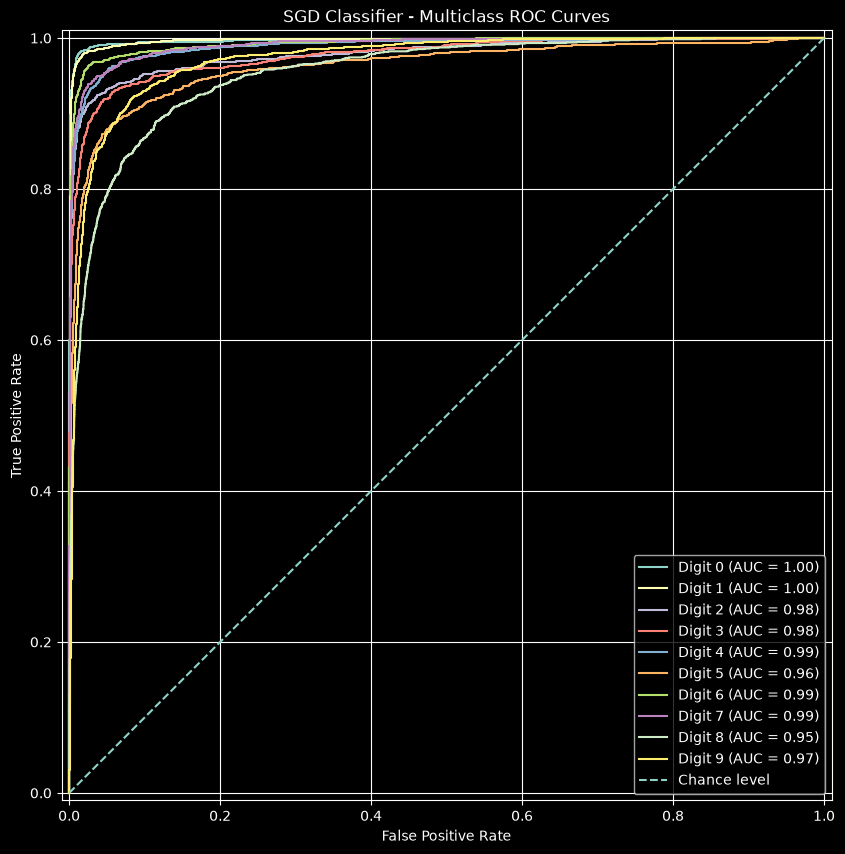

In [13]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    classification_report, roc_auc_score, RocCurveDisplay
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# Initialize and train the model
sgd_clf = SGDClassifier(random_state = 42)
print("Training SGD classifier...")
t_start = time.perf_counter()
sgd_clf.fit(X_train, y_train)
t_end = time.perf_counter()

# Training Information
print("Train stats: \n"
      f"\nIterations to converge: {sgd_clf.n_iter_}"
      f"\nTraining time: {(t_end - t_start):.2f} seconds")

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = sgd_clf.predict(X_test)
# Get predicted probabilities for positive class, for AUC
y_score = sgd_clf.decision_function(X_test)

y_test_bin = label_binarize(y_test, classes=sgd_clf.classes_)
roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(sgd_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_score[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("SGD Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()



### Interpretation

Before diving into the results, an extensions of what each metric is does is to be done:



#### Confusion Matrix
A confusion matrix is a basis for many other metrics. It is a tabular summary for classifier models, by comparing the model predictions against actual true labels. Predications are broken down into four quadrants:
* True Positive(TP); Model asserts entry belongs to class x, entry belongs to class
* False Positive(FP); Model asserts entry belongs to class x, entry does not belong to class
* True Negative(TN); Model asserts entry does not belong to class x, entry does not belong to class
* False Negative(FN); Model asserts entry does not belong to class x, entry does belong to class

For multiclass models, where there are more than 2 classes, the confusion matrix is displayed as rows and columns, this grid represents classes; The row(y axis) is the actual class and columns(x axis) for predicted class. The intersection between a row and column contain the number of predictions made for that combination of actual and predicted classes.

For example, if the actual class is 1 and the predicted class is also 1, the prediction is a True Positive(TP) for class 1. If the actual class is 1 but the model predicts class 2, the prediction is a False Negative(FN). Both these insistence increment the plots on the grid, this gives the chance to track where the model is "getting confused", and adjustments can be made.

The diagonal of the confusion matrix therefore represents correct predictions, while values outside the digonal represent misclassifications. When evaluating an indivdual class, that remaining predictions can be interpreted as TP, TN, FP and FN relative to that class.

#### Accuracy
A classifier accuracy is the ratio of correct predictions to total number of predictions.

_Formula for multi-class accuracy_ -> $$Accuracy = (Number Of Correct Predictions) / (Total Predictions)$$

Accuracy provides a simple measure of the model's overall performance. Where a higher accuracy indicates that the classifier is correctly predicting a greater proportion of the dataset.
However, accuracy can be misleading when the dataset is imbalanced, in where some classes could contain substantially more samples than others. For example, consider the following:

You have 2 classes, class 1 with 2000 samples, and class 2 with 200 samples. if the classifier correctly identifies all 2000 class 1 samples, but incorrectly classifies every class 2 sample, the model would still achieve:
$$
Accuracy = \frac{2000}{2200}
$$

$$
\therefore A = \% 90.9
$$
Despite the seemly high accuracy, the classifier has completely failed to identify class 2. The large number of class 1 samples, completely mask the poor performance of the minority class.

For this reason, Accuracy should always been looked at alongside with other classification metrics, such as precision, recall and f1, particular when datasets that contain class imbalance. Other metrics can help provide deeper insight into how the classifier performs on individual classes rather than only measuring overall proportion of correct predictions. Relying on accuracy alone will give a potentially misguided view on model performance.

#### Precision
Precision measures how often a classifier is correct when it predicts a particular class. Unlike accuracy, which considers the proportion of all correct predictions, precision focuses on the correctness of the models positive predictions for each class.

For a multiclass classifier, precision can be calculated for each class using One-Vs-Rest approach. When evaluating class (i), that class is treated as the positive class, while all other classes are treated as negative.

First taking the precision of each class using One-Vs-Rest, then choosing an aggregation method such as maco, weighted, or micro. This gives a much clearer picture of what the classifier is predicting on a grander scale. As the dataset and task required of our classifiers we will show Precision using the macro methods, in which treats all classes as equally, as the performance requires all classes to be predicted with high accuracy.

_For each class i_
$$
Precision_i = \frac{TP_i}{TP_i+FP_i}
$$

A high precision indicates that when the classifier predicts a particular class, it is usually correct. When the precision is low, this indicates that the classifier frequently assigns other classes to that class, resulting in higher false positives.

In retrospec of the problem dataset containing multiple classes, an aggregation method can be used to produce a signal precision score across all classes. This  method will use macro averaged precision, witch treats every class equally regardless of the number of samples belonging to said class.

_Where C is the total number of classes_
$$
Precision_{macro} = \frac{1}{C}\sum_{i=1}^{C}Precision_i
$$

Taking the example from accuracy, will compare the results of Precision vs Accuracy:
$$
class_1 = \frac{2000}{2000+200}
$$

$$
\therefore C_1 = \% 90.9
$$

$$
class_2 = \frac{0}{0+0}
$$

$$
\therefore C_1 = \% 0
$$

$$
Precision_{macro} = \frac{100+0}{2}
$$

$$
\therefore Precision_{macro} = \% 45.45
$$

In comparison to accuracy, it can clearly be seen the significant differance in results. Accuracy points to %90.9 yet precision is %45.45, further proving the importance of using additional metrics before making assumptions of performance.

#### Recall
Recall measures the models ability to correctly identify instances belonging to a given class. It focuses on false negatives, measuring how many of the actual instances of a class were successfully identified.

_For each class i_
$$
Recall_i = \frac{TP_i}{TP_i+FN_i}
$$

Recall scoring can help identify where classifiers are placing the right class into the wrong category, further building the metric story scope.

For multiclass problems, once again to get an overview of all classes should be done, using macro recall aggregation.

_For class count C_
$$
Recall_{macro} = \frac{1}{C}\sum_{i=1}^{C}Recall_i
$$

We can compare the differance with precision:
$$
Recall_1 = \frac{2000}{2000+0}
$$

$$
\therefore Recall_1 = \% 100
$$

$$
Recall_2 = \frac{0}{0+200}
$$

$$
\therefore Recall_2 = \% 0
$$

$$
Recall_{macro} = \frac{100+0}{2}
$$

$$
\therefore Recall_{macro} = \% 50
$$

With the results of macro recall, it can be seen that there are further shortcoming of the classifier. Particularly with misidentifying class 2. Furthermore, the complained results are paving a clearer pictured of how the classifier is predicting, giving a good place to start tuning for better outcomes.

#### F1 Score
F1 Score is a powerful metric by itself. Within multi-class problems, each classification gets its own f1 score built from the harmonic mean of recall and precision, and with the other metrics, applying a macro method to combine results.

_For each class i_

$$
F-1_i = \frac{2 \cdot Precision_i \cdot Recall_i}{Precision_i+Recall_i}
$$

Using the above rcall and precision we can calculate the f1 score for each, followed by the f1 macro.
$$
F-1_1 = \frac{2 \cdot 90.9 \cdot 100}{90.9 + 100}
$$

$$
\therefore F-1_1 = \% 95.23
$$

$$
F-1_2 = \frac{2 \cdot 0 \cdot 0}{0 + 0}
$$

$$
\therefore F-1_2 = \% 0
$$

$$
F-1_{macro} = \frac{95.25 + 0}{2}
$$

$$
\therefore F-1_{macro} = \% 47.63
$$

F1 scoring can further help get a balanced idea of the classifiers overall performance, without having a large basis towards over achieving classes. All the metrics provide value in understanding the models being used, and help paint a clear picture of what's going right, and what is going wrong, so that tuning and feature engineering changes can give a clear output.

#### ROC-AUC

ROC-AUC(Receiver Operating Characteristic - Area Under the Curve) measure the models ability to distinguish between different classes across varying classification thresholds. Evaluating the relationship between the True Positive Rate and the False Positive Rate, measuring how effectively the classifier separates positive instances from the negative instances.

The ROC plots the following against each other:

_for each class i_

$$
True Positive Rate(TPR)_i = \frac{TP_i}{TP_i+FN_i}
$$

$$
False Positive Rate(FPR)_i = \frac{FP_i}{FP_i+TN_i}
$$

The AUC calculates the area beneath the ROC curve, providing a single numerical measurement of the classifier discriminative ability. Being an AUC score closer to 1 indicates stronger class separation behavior, and scores siting around 0.5 show mostly random discrimination, anything below 0.5 is proving worse performance then if the classifier were randomly guessing.

For multiclass problems, ROC-AUC can be calculated using a One-Vs-Rest approach. Each class evaluated against all other classes, producing an individual score for each class. Again implementing Macro averaging to get a healthy value from the collective scores, assuring all classes are treated equally.

Unlike precision, recall F1, ROC-AUC evaluates the classifier across multiple decision thresholds rather than relying on the default classification decisions. With the border understanding of how the model is distinguishing classes from each other, it can help identify whether classification errors are caused by poor class separation or the selected decision boundaries.

### SGD Classifier Metrics
The baseline SGD classifier archived an overall accuracy of 87.44%, with macro averaged precision of 88.94%, recall of 87% and F1 of 87.02%. This indicates the classifier can distinguish the majority of the MNIST digits effectively, although its performance varies considerably class to class.

The classification report highlights the variations. Digits 0, 1, 6 and 7 achieved relatively strong F1 of all > 92%, indicating these classes as being well separated by the model. Although in contest, digit 5 produced the lowest recall at 52% and the lowest F1 score of 68%, clearing showing the classifier struggling to correctly identify many instances of the digit 5.

The confusion matrix gives further insight into these errors. Of the actual digit 5 instances, 372 were classified as 8, and 101 classified as 3. This suggests that the SGD classifier is struggling to distinguish certain visually simular digits. further with digit 8, achieving a high recall of 92%, yet its precision was only 62%, showing that many samples predicted to be 8 belonged to another class.

The macro ROC-AUC score of 98.09% is much higher than the classification accuracy. this indicates that although the classifier makes noticeable number of incorrect final prediction, it decisions score provide strong separation between classes.

Overall, the baseline SGD classifier provides a good starting point, but the confusion matric revels clear areas for improvement, particularly in visually similar digits such as 5, 8, 3 and 9. These errors a useful starting point for seeing how feature engineering, dimension reduction, ensemble methods and hyperparameter tuning can effect the models ability to better designate classes that cluster closely.



### Decision Tree Classifier

A Decision Tree Classifier is a supervised machine learning algorithm that categorizes data by recursively splitting said data into smaller subsets, these subsets are split using feature base rules. Having the topmost node(Root) as the starting point, and the bottom leaf nodes as class categories.

As the DTC has benefits of being very interpretable, and requires minimal data preparation, it is very susceptible to overfitting and high variance. Trees can easily grow do deep, with a high sensitively to noise, these classifiers get great benefits from tuning hyperparameters. Although changes to parameters can create another problem, any changes to the training data or methods can completely restructure trees.

Training DTC classifier...
Train stats: 

Tree depth: 44
Tree nodes: 7557
Tree leafs: 3779
Training time: 8.98 seconds
Accuracy: 87.42%
Precision: 87.24%
Recall: 87.25%
F1 Score: 87.24%
ROC-AUC Score: 92.93%
Confusion Matrix: 
[[1287    4    8    8    6   22   16    2   20    8]
 [   1 1514   19   11    4    5    3   10    8    0]
 [  21   10 1186   39   17   17   26   23   36   23]
 [   8   13   37 1202   10   59    5   22   32   40]
 [  11    7   20   13 1193    7   15   18   20   61]
 [  20   10   12   62   16 1044   29   12   31   27]
 [  28   10   22    3   21   37 1217    3   27    7]
 [   4   13   22   14   17   12    2 1331   11   33]
 [  20   13   37   33   29   37   28   17 1104   47]
 [  12    8   15   27   66   25    8   32   37 1161]]
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      1381
           1       0.95      0.96      0.95      1575
           2       0.86      0.85      0.85      1398
  

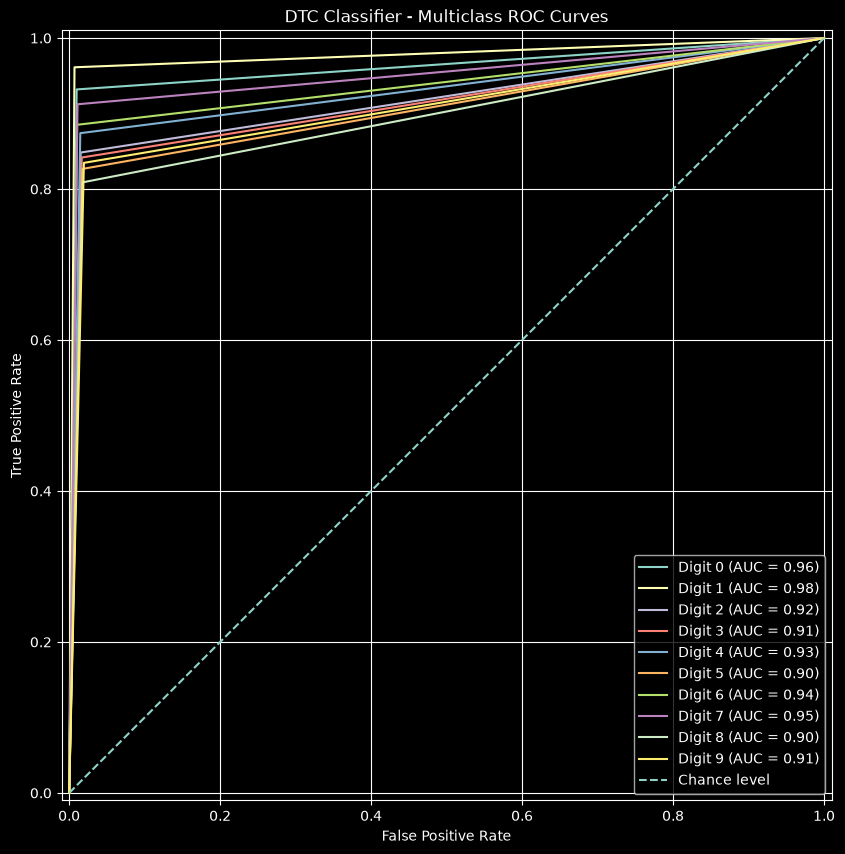

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    classification_report, roc_auc_score, RocCurveDisplay
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# Initialize and train the model
dtc_clf = DecisionTreeClassifier(random_state = 42)
print("Training DTC classifier...")
t_start = time.perf_counter()
dtc_clf.fit(X_train, y_train)
t_end = time.perf_counter()

# Training Information
print("Train stats: \n"
      f"\nTree depth: {dtc_clf.get_depth()}"
      f"\nTree nodes: {dtc_clf.tree_.node_count}"
      f"\nTree leafs: {dtc_clf.get_n_leaves()}"
      f"\nTraining time: {(t_end - t_start):.2f} seconds")

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = dtc_clf.predict(X_test)
# Get predicted probabilities for positive class, for AUC
y_proba = dtc_clf.predict_proba(X_test)

# Binarise actual labels
y_test_bin = label_binarize(
    y_test,
    classes=dtc_clf.classes_
)

roc_auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(dtc_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("DTC Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

### Interpretation

A major note in comparison from SGD to DT Classifiers, is the speed of training, with DT Classifier training 7.5 times faster.

The overall metric for accuracy compared to the SGD classifier is almost the same, yet an overview shows a much more balanced categorization, even within the harder to class 5,3,8 and 9, siting at no lower than 82% for F1, recall and precision. This indicates a much better lower end performance.

The baseline Decision Tree Classifier achieved an accuracy of 87.42%, and with macro averaged precision, recall and f1-scores of 87.24%, 87.25%, 87.24%. Such a close alignment between these metrics suggest a relatively balanced classification performance throughout the dataset.

The classification reports highlights digit 1 as the models strongest class prediction, achieving a F1 score of 95%. With the lowest F1 score reserved for digit 8, siting at 82%, indicating a difficulty with distinguishing 8 from other classes.

Within the confusion matrix, patrons of misclassification can be identified. The largest confusion occurred between digits 9 and 4, with 66 actual 9s classed as 4s, and 61 actual 4s classed as 9. Additionally, it can be seen 3 and 5 had overlapping behavior, pointing towards confusion coming from the visual closeness of these digits.

More so, the classifier achieved a macro ROC-AUC score of 92.93%, showing reasonably strong class discrimination. As this is considerably lower than the SGD classifier, there accuracy is tightly bound with each other.

In terms of communally performance, the DTC manage to complete training within 8.98 seconds, 7.5 times faster than the SGD classifier. Although faster, the DTC has a complex structure of 7,557 nodes, 3,779 leaves and a max depth of 44.

Overall the DTC provides a clearly competitive baseline, with good balanced classifications and fast training. The lower ROC-AUC and tree complexity present opportunities for further optimizations, particular through modifying tree max depth, and how dimensionality reduction and or ensemble methods can improve performance.



## Feature Engineering

Now with a baseline for both models, we can try optimizing performance with some feature engineering. some of which includes:

* Cleaning:
    * Handling missing values
    * removing duplicates
    * detecting and handling anomalous data
* Transformation
    * Normalization, scale numerical features to prevent model bias
    * Dimensionality reduction
* Balance data
    * Assure enough data is filled in each feature, making sure not to oversample or undersample maintaining model fairness and accuracy
* Encoding
    * one hot encoding
    * label encoding
    * Creating numerical data out of non-numerical features

It's important to visualize and modify feature, as bugs in the pip-line and unfit data can cause errors or skewed output in the models.

### Normalisation With SGD Classifier

Non-Normalized pixel range: 0.0-255.0
Normalized pixel range: 0.0-1.0
Training SGD classifier...
Train stats: 

Iterations to converge: 35
Training time: 8.67 seconds
Accuracy: 90.93%
Precision: 90.98%
Recall: 90.73%
F1 Score: 90.77%
ROC-AUC Score: 98.37%
Confusion Matrix: 
[[1358    0    3    6    0    3    5    0    3    3]
 [   0 1534    8   10    1    7    3    5    7    0]
 [  16   11 1245   36   10    5   22   22   24    7]
 [   7    3   34 1313    1   26    4   12   14   14]
 [   8   11   12    6 1216    2    9    3   20   78]
 [  16    8   13   94    9 1033   18   11   40   21]
 [  17    2   10    1    7   12 1313    0   13    0]
 [   6    7   23    8    6    1    0 1370    5   33]
 [  14   36   22   74    8   36    7    9 1115   44]
 [  13   12    1   35   26   17    2   47    5 1233]]
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96      1381
           1       0.94      0.97      0.96      1575
        

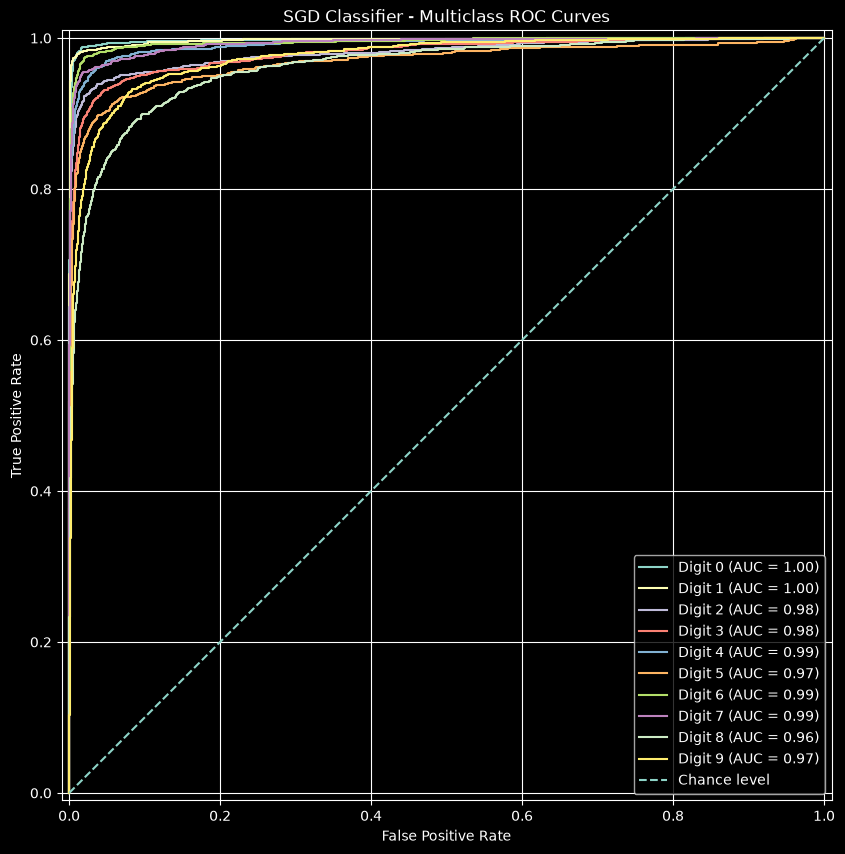

In [23]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    classification_report, roc_auc_score, RocCurveDisplay
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# Check and amend Normalization
print(F"Non-Normalized pixel range: {X_train.min().min()}-{X_train.max().max()}")
X_train_scaled = X_train / 255.0
X_test_scaled = X_test / 255.0
print(f"Normalized pixel range: {X_train_scaled.min().min()}-{X_train_scaled.max().max()}")


# Initialize and train the model
sgd_clf = SGDClassifier(random_state = 42)
print("Training SGD classifier...")
t_start = time.perf_counter()
sgd_clf.fit(X_train_scaled, y_train)
t_end = time.perf_counter()

# Training Information
print("Train stats: \n"
      f"\nIterations to converge: {sgd_clf.n_iter_}"
      f"\nTraining time: {(t_end - t_start):.2f} seconds")

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = sgd_clf.predict(X_test_scaled)
# Get predicted probabilities for positive class, for AUC
y_score = sgd_clf.decision_function(X_test_scaled)

y_test_bin = label_binarize(y_test, classes=sgd_clf.classes_)
roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(sgd_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_score[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("SGD Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()




### Interpretations

Following the application of pixel intensity normalisation, the SGD classifier demonstrated a substantial improvement  across it metrics

Accuracy now sits at 90.93%, a 3.49 point jump, while the F1 score improved from 87.02% to 90.77%. This indicates that normalisation improves the classifiers overall predictive performance, and the balance between perception and recall.

A very notable improvement was observed in the recognition of 5, from 52% to 82%, a 30 point jump. The confusion matrix also demonstrated a significant reduction in misclassification between 5 and 8, suggesting an improvement of models ability to differentiate digits that look alike.

Further, normalisation considerably improved computation speed, from 67.34 seconds down to 8.67 seconds, and even the number of iteration required for convergence decreased from 375 to 35.

These results demonstrate that normalising pixel intensity to the 0-1 range can provide substantial benefits to SGD classifiers, both improving performance and efficiency.

### Normalisation With DT Classifier

Training DTC classifier...
Train stats: 

Tree depth: 44
Tree nodes: 7557
Tree leafs: 3779
Training time: 8.78 seconds
Accuracy: 87.43%
Precision: 87.25%
Recall: 87.25%
F1 Score: 87.25%
ROC-AUC Score: 92.93%
Confusion Matrix: 
[[1287    4    8    8    6   22   16    2   20    8]
 [   1 1514   19   11    4    5    3   10    8    0]
 [  21   10 1186   39   17   17   26   23   36   23]
 [   8   13   37 1202   10   59    5   22   32   40]
 [  11    7   20   13 1193    7   15   18   20   61]
 [  20   10   12   62   16 1044   29   12   31   27]
 [  27   10   22    3   21   37 1218    3   27    7]
 [   4   13   23   14   17   12    2 1330   11   33]
 [  20   13   37   33   29   37   28   17 1105   46]
 [  12    8   15   27   66   25    8   32   37 1161]]
Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      1381
           1       0.95      0.96      0.95      1575
           2       0.86      0.85      0.85      1398
  

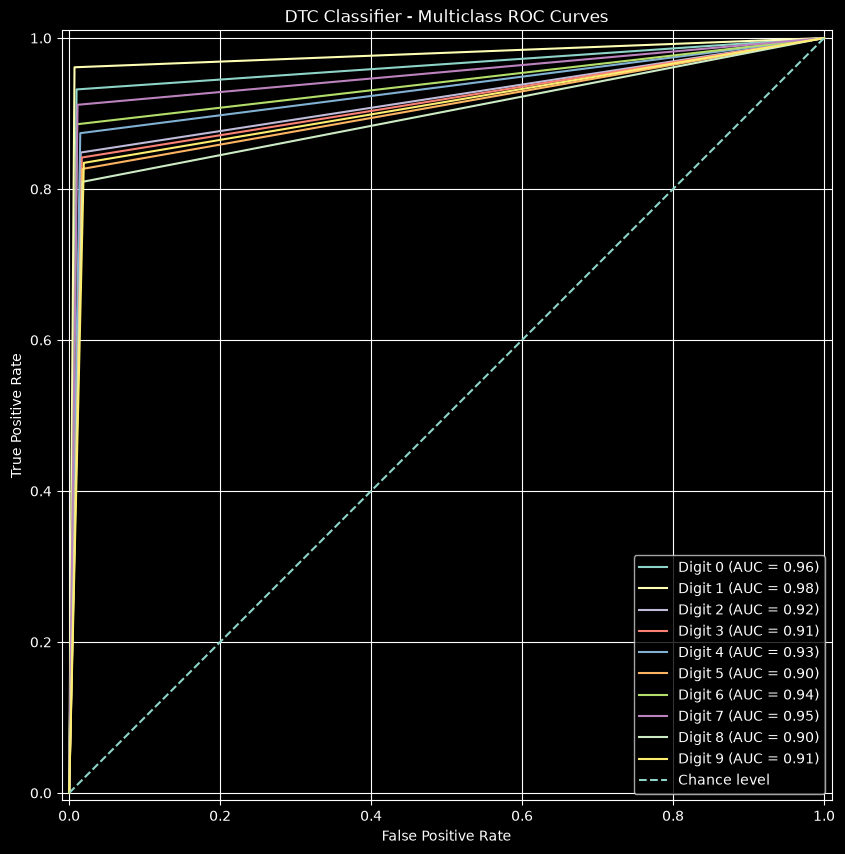

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    classification_report, roc_auc_score, RocCurveDisplay
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# Initialize and train the model
dtc_clf = DecisionTreeClassifier(random_state = 42)
print("Training DTC classifier...")
t_start = time.perf_counter()
dtc_clf.fit(X_train_scaled, y_train)
t_end = time.perf_counter()

# Training Information
print("Train stats: \n"
      f"\nTree depth: {dtc_clf.get_depth()}"
      f"\nTree nodes: {dtc_clf.tree_.node_count}"
      f"\nTree leafs: {dtc_clf.get_n_leaves()}"
      f"\nTraining time: {(t_end - t_start):.2f} seconds")

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = dtc_clf.predict(X_test_scaled)
# Get predicted probabilities for positive class, for AUC
y_proba = dtc_clf.predict_proba(X_test_scaled)

# Binarise actual labels
y_test_bin = label_binarize(
    y_test,
    classes=dtc_clf.classes_
)

roc_auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(dtc_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("DTC Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

Following the application of pixel intensity normalisation, the DT Classifier demonstrated an almost completely 0 change. As stated in the description pf DT Classifiers, making scaling changes is not a requirement for the DT to function well, the results prove this statement as true.

Moving on the focus will be just on the SGD classifier, as results returned are more interpretable and paint a better picture of change through each iteration of process.

### Normalisation + PCA at 95 With SGD Classifier

Original Feature: 784
Reduced Feature: 154
Explained variance: 0.9503945587155499
Number of components: 154
Training SGD classifier...
Train stats: 

Iterations to converge: 49
Training time: 3.45 seconds
Accuracy: 91.15%
Precision: 91.01%
Recall: 91.03%
F1 Score: 91.01%
ROC-AUC Score: 98.17%
Confusion Matrix: 
[[1339    0    3    1    1   13    8    0   11    5]
 [   1 1521   14    9    0    9    3    4    8    6]
 [   4    5 1263   19   15   14   22   20   30    6]
 [   6    3   42 1269    2   53    8   11   20   14]
 [   3    4    8    8 1232    2   12    0   18   78]
 [  12    2   17   41   11 1088   29    6   37   20]
 [  13    2   13    0    6   16 1317    0    7    1]
 [   6    4   18    4   16    7    0 1353    6   45]
 [   9   14   24   43   12   56   14    6 1162   25]
 [   7   12    3   31   52   16    1   33   19 1217]]
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1381
           1       0.97 

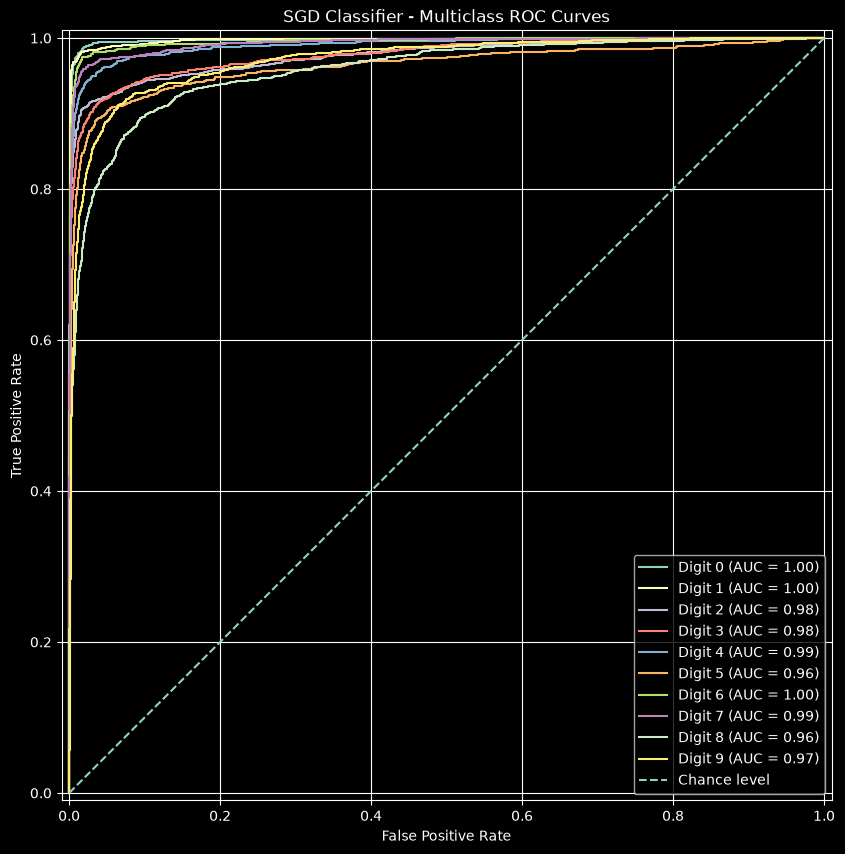

In [25]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, \
    classification_report, roc_auc_score, RocCurveDisplay
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.decomposition import PCA

print("Original Feature:", X_train_scaled.shape[1])
# Retain 95% variance after reduction
pca = PCA(n_components = 0.95)
# Fit and tranform training data
X_train_pca = pca.fit_transform(X_train_scaled)
#  Apply the fitted tranfomation to testing data
X_test_pca = pca.transform(X_test_scaled)

print("Reduced Feature:", X_train_pca.shape[1])
print("Features new Shape", X_train_pca.shape)
print("Explained variance:",  pca.explained_variance_ratio_.sum())
print("Number of components:", pca.n_components_)

# Initialize and train the model
sgd_clf = SGDClassifier(random_state = 42)
print("Training SGD classifier...")
t_start = time.perf_counter()
sgd_clf.fit(X_train_pca, y_train)
t_end = time.perf_counter()

# Training Information
print("Train stats: \n"
      f"\nIterations to converge: {sgd_clf.n_iter_}"
      f"\nTraining time: {(t_end - t_start):.2f} seconds")

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = sgd_clf.predict(X_test_pca)
# Get predicted probabilities for positive class, for AUC
y_score = sgd_clf.decision_function(X_test_pca)

y_test_bin = label_binarize(y_test, classes=sgd_clf.classes_)
roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(sgd_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_score[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("SGD Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

### Interpretation

Following the application of PCA with a 95% explained variance threshold, the SGD Classifier had slight changes in performance, mostly positive with a few negative. The PCA did give a substantial reduction to the training time again.

Accuracy increased from 90.93% to 91.15% while the F1 score improved from 90.77% to 91.01%. This suggests dimensionality reduction retained sufficient information for effective classification, while potentially removing redundant or less informative feature variation.

Overview of the confusion matrix also identified improvements in the recognition of several digit categories, mainly with 3 and 8. However, performance improvement was not completely uniform across all classes, as F1 scores for 4 and 6 declined.

Computational efficiency improved considerably. Training time reduced about 60%, but the number of iterations increased from 35 to 49, showing that fewer dimensions can optimize computation cost of individual iterations.

The ROC-AUC deceased slightly from 98.37% to 98.17%, am indication that final classification performance did not translate to improved class discrimination.

Tge PCA transformation reduced the original 784 input features to 154 principal components,  representing an 80.36% reduction in dimensionality while still retaining 95% of the original dataset variance.

These finding suggest that PCA provided a more efficient feature representation while maintaining, and marginally improving, the predictive performance of the SGD Classifier.

### PCA-Projected Pixel Influence

SGD coefficient shape: (10, 154)
PCA component shape: (154, 784)
Pixel influence shape: (10, 784)


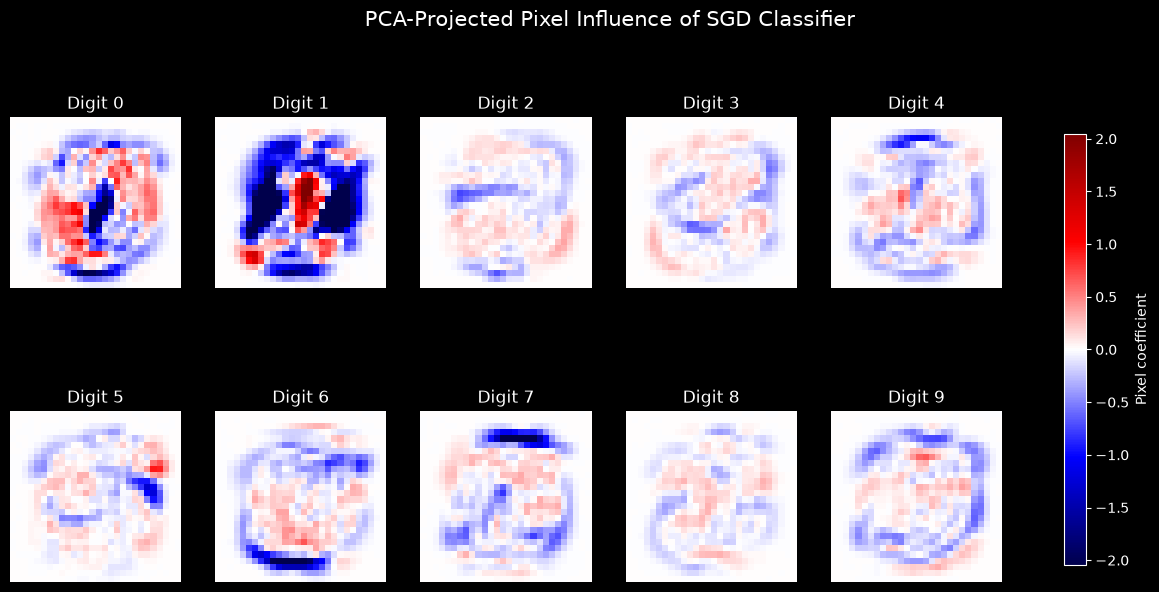

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

print("SGD coefficient shape:", sgd_clf.coef_.shape)

# PCA components map the 154 PCA features back to the
# original 784 pixel feature space
print("PCA component shape:", pca.components_.shape)

# Project SGD coefficients back into the original pixel space
pixel_coefficients = sgd_clf.coef_ @ pca.components_

print("Pixel influence shape:", pixel_coefficients.shape)

# Calculate a shared colour range across all classes
max_influence = np.percentile(
    np.abs(pixel_coefficients),
    99
)
# Set plot body
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

# Loop through each class drawing heat map of pixel intensity
for index, (digit, ax) in enumerate(zip(sgd_clf.classes_, axes.ravel())):
    # Get influence value
    influence = pixel_coefficients[index]

    # Map back to 28x28 shape
    influence_map = influence.reshape(28, 28)

    # Set values building on last
    image = ax.imshow(
        influence_map,
        cmap="seismic",
        vmin=-max_influence,
        vmax=max_influence
    )

    ax.set_title(f"Digit {digit}")
    ax.axis("off")

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label="Pixel coefficient",
    shrink=0.8
)

plt.suptitle(
    "PCA-Projected Pixel Influence of SGD Classifier",
    fontsize=15
)

plt.show()

To further investigate the effects if PCA on the original feature space, the trained SGD classifiers coefficients were projected back onto the original 784 pixel features using hte PCA component matric. archived through matrix multiplication, mapping the weights from the 154 dimensional representation back to the original 28x28 grid.

The resulting heatmaps visualise the positive and negative influence of the individual pixes on each classification. Positive coefficients contributing to prediction, while negative to contribute against it.
The matrix equation:
$$
W_{pixel} = W_{SDG} \cdot W{PCA}
$$

## Hyperparameter tuning and evaluation

Up until now we have been manually making changes to the data and maintaining the same default setting for the classifier models. It's time to speed up the process in a safe and clean manner, on which can be done using a combination of sklearns Pipelines pushing into a gridsearch. The Pipline giving a clean flow and iteration of the data, avoiding data leaks; and the GridSearch to automate flipping in and out different passed in parameters with that said pipline. Once completed gridsearch can return the best combination of parameters based on a scoring metrics, normally being F1 macro.

Furthermore, gridsearch implements a three-fold cross-validation method by default, using two folds for training, and one for validation and scoring. Each iteration flips around the folds, stoping the model creating a basis with testing or training data.

### Building up SGD Classifier

In [37]:
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV

# Constructing the pipline
sdg_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),         # Scale data: 0-1
    ("pca", PCA(n_components = 154)),   # Maintain same PCA principal components that was 95% variance
    ("classifier", SGDClassifier()),    # Set as SGD Classifier
])

# Defining parameter searching space
sgd_params = {
    "classifier__loss": ["hinge", "log_loss"],
    "classifier__alpha": [0.0001, 0.001, 0.01, 0.1],
    "classifier__max_iter": [500, 1000, 1250],
    "classifier__penalty": ["l1", "l2", "elasticnet"],
}

# Config gridsearch
sdg_grid = GridSearchCV(
    estimator=sdg_pipeline,     # Use set pipline
    param_grid=sgd_params,      # Use set params
    scoring="f1_macro",         # Use f1 scoring with macro averaging
    cv=5,                       # Use 5 folds
    n_jobs=-1,                  # Continue until complete
    verbose=1,
)

# Train and optimize using origin data
sdg_grid.fit(X_train, y_train)

print("Best parameters:")
print(sdg_grid.best_params_)
print(sdg_grid.best_score_)



Fitting 5 folds for each of 72 candidates, totalling 360 fits


C:\Users\Isaac\SAE\tri_3\CST261\machine_learning_workflow\.venv\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters:
{'classifier__alpha': 0.0001, 'classifier__loss': 'log_loss', 'classifier__max_iter': 1000, 'classifier__penalty': 'l2'}
0.9094747377714281


### Building up DT Classifier

In [36]:
from sklearn.tree import DecisionTreeClassifier

# Build pipline, does not need scaling or PCA
dtc_pipeline = Pipeline([
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Build params
dtc_params = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [10, 20, 30, None],    # Set tree depth
    "classifier__min_samples_split": [2, 5, 10],    # Set minimum to split node
    "classifier__min_samples_leaf": [1, 2, 5]       # Set minimum needed in each leaf
}

# Build gridsearch
dtc_grid = GridSearchCV(
    estimator=dtc_pipeline,
    param_grid=dtc_params,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)
# Train and optimize on origin data
dtc_grid.fit(X_train, y_train)

print("Best Parameters:", dtc_grid.best_params_)
print("Best CV Macro F1:", dtc_grid.best_score_)

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best Parameters: {'classifier__criterion': 'entropy', 'classifier__max_depth': 30, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
Best CV Macro F1: 0.8731413263386095


### Grab the best of the bunch, run on test data

#### SGD Classifier

Accuracy: 91.31%
Precision: 91.17%
Recall: 91.19%
F1 Score: 91.17%
ROC-AUC Score: 98.40%
Confusion Matrix: 
[[1337    0    3    1    1   15   10    0   10    4]
 [   1 1522   11    9    0   12    3    4    8    5]
 [   5    6 1264   14   19    8   23   20   32    7]
 [   7    2   34 1263    2   59    7   14   26   14]
 [   3    4    9    6 1236    0   16    3   20   68]
 [  10    3   10   46   12 1087   25    7   38   25]
 [   9    2    8    0    8   16 1321    0   11    0]
 [   5    4   19    5    9    4    0 1369    6   38]
 [   9   14   21   32   10   59   13    5 1176   26]
 [   7   12    3   23   55   18    2   44   18 1209]]
Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1381
           1       0.97      0.97      0.97      1575
           2       0.91      0.90      0.91      1398
           3       0.90      0.88      0.89      1428
           4       0.91      0.91      0.91      1365
           5 

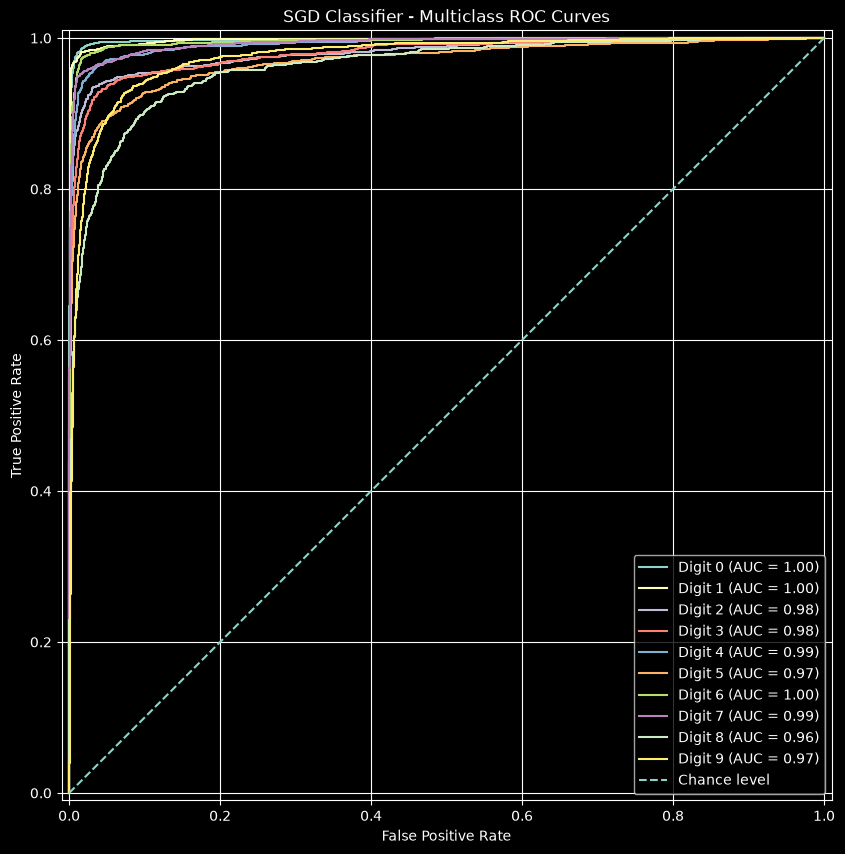

In [40]:
sgd_clf = sdg_grid.best_estimator_



# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = sgd_clf.predict(X_test)
# Get predicted probabilities for positive class, for AUC
y_score = sgd_clf.decision_function(X_test)

y_test_bin = label_binarize(y_test, classes=sgd_clf.classes_)
roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(sgd_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_score[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("SGD Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

##### Interpretation

Comparing the tuned SGD Classifier with the base SGD Classifier, there is a considerable improvement in classification performance. The tuned model with an accuracy of 91.31% and a macro f1-score of 91.17%, compared to 87.44% and 87.02% in the first model.

The most significant improvement, was within the classification of the digits 5 and 8. The first model only achieving 52% recall, with 372 instances incorrectly classified as 8. with the second model substantially reducing confusion, bringing 5's recall up to 86%.

Also to note, the second model shows a much more consistent performance across the ten categories, suggesting improved classification boundaries and a much better balance between precision and recall.

Overall, the hyperparameter and feature tuning in combonation demonstrates improved classification, and a more well-balanced performance across the MNIST dataset.

#### DT Classifier

Accuracy: 87.61%
Precision: 87.43%
Recall: 87.43%
F1 Score: 87.42%
ROC-AUC Score: 93.03%
Confusion Matrix: 
[[1294    0   10    7    7   22   17    1   13   10]
 [   1 1511   11   11    3   12    8    6    9    3]
 [  15   10 1182   42   16   14   31   37   38   13]
 [   8    6   29 1213    4   79    8   25   33   23]
 [   6    7   14    4 1177    8   34   19   27   69]
 [  17    6   14   75   11 1031   37    7   37   28]
 [  23    5   29    4   33   25 1230    3   19    4]
 [   3   11   23   19   14    8    3 1327   11   40]
 [  15   10   30   36   14   35   32   10 1135   48]
 [  10    7   10   25   72   34    6   28   34 1165]]
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      1381
           1       0.96      0.96      0.96      1575
           2       0.87      0.85      0.86      1398
           3       0.84      0.85      0.85      1428
           4       0.87      0.86      0.87      1365
           5 

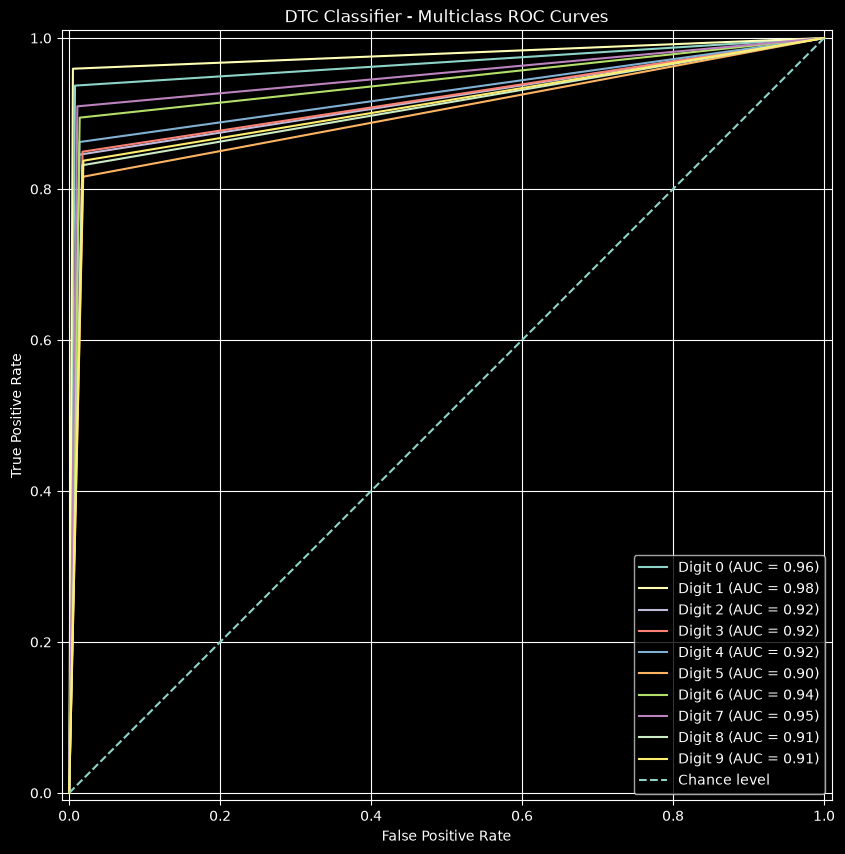

In [42]:
dtc_clf = dtc_grid.best_estimator_

# Testing
# First generate predictions based of none labeled test data, model will attempt to class under a existing label from training data
y_pred = dtc_clf.predict(X_test)
# Get predicted probabilities for positive class, for AUC
y_proba = dtc_clf.predict_proba(X_test)

# Binarise actual labels
y_test_bin = label_binarize(
    y_test,
    classes=dtc_clf.classes_
)

roc_auc = roc_auc_score(y_test_bin, y_proba, average="macro", multi_class="ovr")


# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(dtc_clf.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("DTC Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

## Ensemble techniques

Ensemble techniques and method involve combine multiple machine learning models, often weaker learners, to create a single, more accurate, and reliable prediction. This can help balance variance tradeoffs, reduce overfitting and improve generalisation on unseen date.

Some methods include:
* bagging, in which models are trained in parallel, with each model using different random bootstrap samples of the training data. These are primarily used to reduce variance, creating less overfitting from noisy data.
* Boosting, models are trained sequentially, with each model tasked with correcting errors from previus models. This can reduce bais, and create string learns from weak learns.
* Stacking, Combines a diverse selection of base models, feding predictions into a higher level metamodel. with the goal of capering complex interactions from differance model families to maximise predictive accuracy.
* Voting, in where models combine prediction, and major votes win.

### Random Forest Classifier

Accuracy: 96.72%
Precision: 96.70%
Recall: 96.69%
F1 Score: 96.69%
ROC-AUC Score: 99.89%
Confusion Matrix: 
[[1371    1    0    0    1    0    2    0    5    1]
 [   0 1548    9    7    1    1    2    5    1    1]
 [   8    1 1350    3    6    1    7   14    7    1]
 [   3    1   14 1368    0   14    2   12   12    2]
 [   4    3    1    0 1312    0   10    0    4   31]
 [   5    1    2   17    3 1207   11    2    7    8]
 [   9    2    1    0    3    4 1350    0    6    0]
 [   1    5   13    0    9    0    0 1414    3   14]
 [   3    3    8    7    3   11    3    0 1308   19]
 [   8    7    1   16   18    4    1   12   11 1313]]
Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1381
           1       0.98      0.98      0.98      1575
           2       0.96      0.97      0.97      1398
           3       0.96      0.96      0.96      1428
           4       0.97      0.96      0.96      1365
           5 

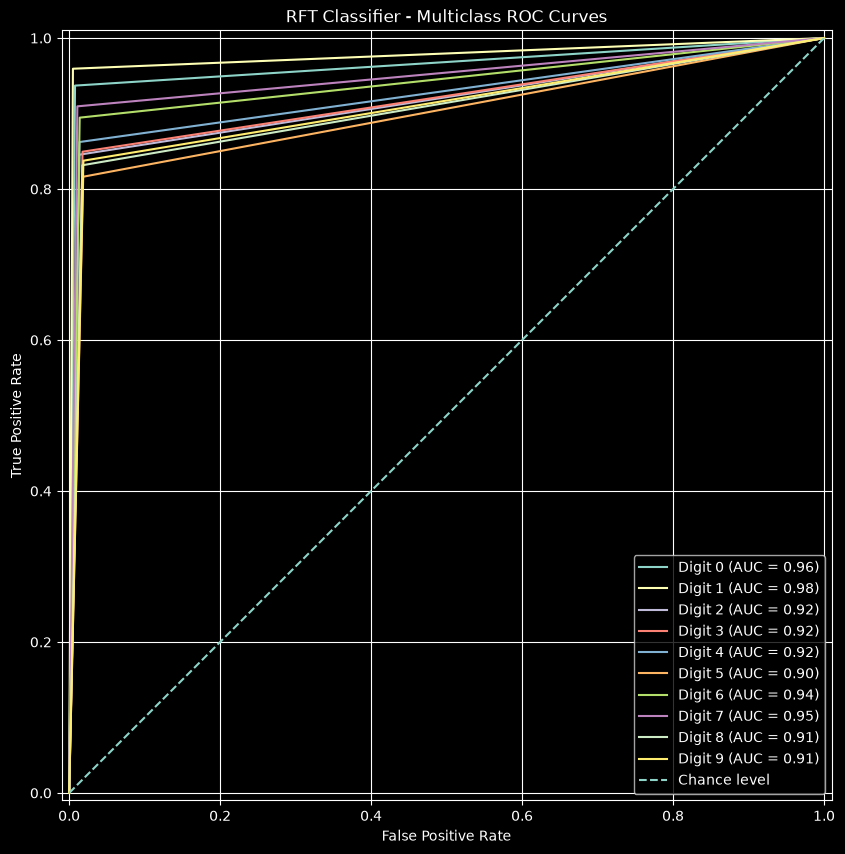

In [43]:
from sklearn.ensemble import RandomForestClassifier

# Constructing the pipeline
rfc_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=100,       # Creating 100 DT classifers to feed the forest
        random_state=42,
        n_jobs=-1
    )),
])

# Train model
rfc_pipeline.fit(X_train, y_train)

# Generate predictions
y_pred = rfc_pipeline.predict(X_test)

# Generate predicted probabilities for ROC-AUC
y_score = rfc_pipeline.predict_proba(X_test)

y_test_bin = label_binarize(y_test, classes=rfc_pipeline.classes_)

roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")

# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(rfc_pipeline.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("RFT Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()

### Voting Classifier

Accuracy: 87.61%
Precision: 87.43%
Recall: 87.43%
F1 Score: 87.42%
ROC-AUC Score: 99.15%
Confusion Matrix: 
[[1294    0   10    7    7   22   17    1   13   10]
 [   1 1511   11   11    3   12    8    6    9    3]
 [  15   10 1182   42   16   14   31   37   38   13]
 [   8    6   29 1213    4   79    8   25   33   23]
 [   6    7   14    4 1177    8   34   19   27   69]
 [  17    6   14   75   11 1031   37    7   37   28]
 [  23    5   29    4   33   25 1230    3   19    4]
 [   3   11   23   19   14    8    3 1327   11   40]
 [  15   10   30   36   14   35   32   10 1135   48]
 [  10    7   10   25   72   34    6   28   34 1165]]
Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      1381
           1       0.96      0.96      0.96      1575
           2       0.87      0.85      0.86      1398
           3       0.84      0.85      0.85      1428
           4       0.87      0.86      0.87      1365
           5 

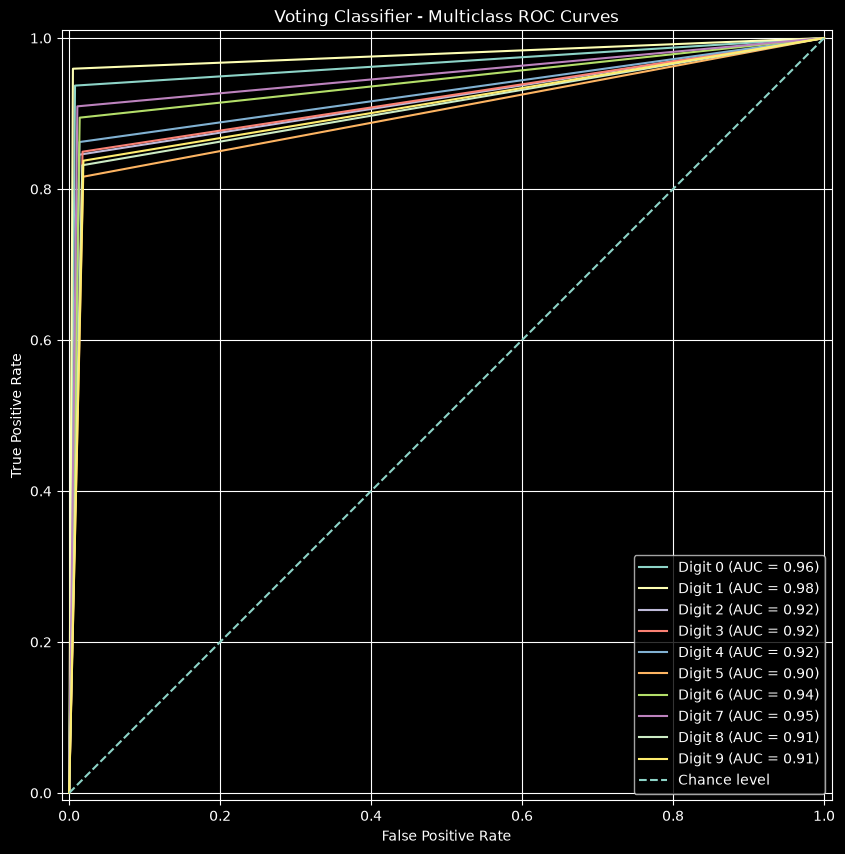

In [44]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

# Copy tuned models
sgd_voting = clone(sdg_grid.best_estimator_)
# Make sure right params are set, if log_loss isnt set the voter will break
sgd_voting.set_params(classifier__loss="log_loss")

dtc_voting = clone(dtc_grid.best_estimator_)

#  Construct voting classifier
voting_clf = VotingClassifier(
    estimators=[
        ("sgd", sgd_voting),
        ("dtc", dtc_voting),
    ],
    voting="soft",      # Set voting to soft
    n_jobs=-1
)

# Train
voting_clf.fit(X_train, y_train)
y_pred = voting_clf.predict(X_test)
y_score = voting_clf.predict_proba(X_test)


y_test_bin = label_binarize(y_test, classes=voting_clf.classes_)

roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")

# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(rfc_pipeline.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("Voting Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()


### Building a tower: Stacking

C:\Users\Isaac\SAE\tri_3\CST261\machine_learning_workflow\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Isaac\SAE\tri_3\CST261\machine_learning_workflow\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\Isaac\SAE\tri_3\CST261\machine_learning_workflow\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.


Accuracy: 96.91%
Precision: 96.88%
Recall: 96.88%
F1 Score: 96.88%
ROC-AUC Score: 99.91%
Confusion Matrix: 
[[1371    1    1    0    0    0    1    0    5    2]
 [   0 1545    6    8    1    1    4    6    1    3]
 [   7    1 1355    4    3    1    5   12    9    1]
 [   2    0   12 1373    0   16    1   10   12    2]
 [   3    2    2    0 1315    0    7    0    8   28]
 [   4    0    1   14    2 1211   10    1   13    7]
 [   7    2    2    0    3    5 1349    0    7    0]
 [   1    4   13    4    6    0    0 1416    2   13]
 [   2    2    6    9    1   11    1    0 1317   16]
 [   5    5    1   15   21    4    1   13   11 1315]]
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1381
           1       0.99      0.98      0.99      1575
           2       0.97      0.97      0.97      1398
           3       0.96      0.96      0.96      1428
           4       0.97      0.96      0.97      1365
           5 

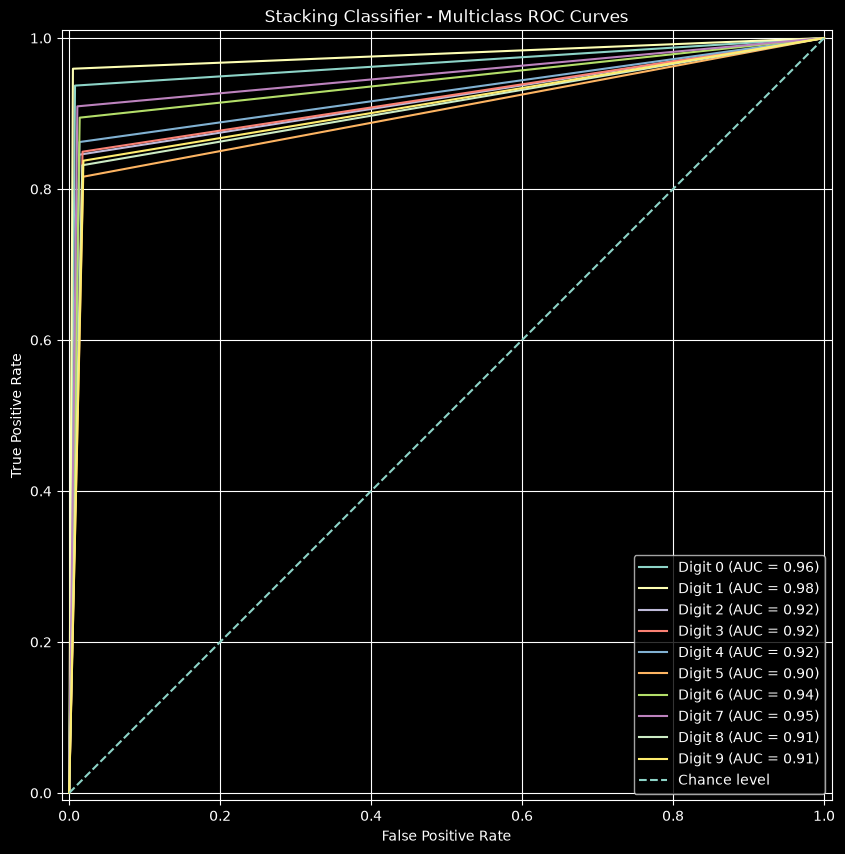

In [45]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# Define base models to feed the beast
base_estimators = [
    ("sgd", clone(sdg_grid.best_estimator_)),
    ("dtc", clone(dtc_grid.best_estimator_)),
    ("rfc", clone(rfc_pipeline)),
    ("vc", clone(voting_clf)),
]

# Construct the Stacking classifier
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(
        max_iter=1000,
    ),
    cv=5,
    stack_method="auto",
    n_jobs=-1
)

stacking_clf.fit(X_train, y_train)
y_pred = stacking_clf.predict(X_test)
y_score = stacking_clf.predict_proba(X_test)

y_test_bin = label_binarize(y_test, classes=stacking_clf.classes_)

roc_auc = roc_auc_score(y_test_bin, y_score, average="macro", multi_class="ovr")

# Print individual metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"Recall: {recall_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")*100:.2f}%")
print(f"ROC-AUC Score: {roc_auc*100:.2f}%")

# Print confusion matrix plus full summary
print(f"Confusion Matrix: \n{confusion_matrix(y_test, y_pred)}")
print(f"Classification Report:\n{classification_report(y_test,y_pred)}")

# Plot ROC curves for each class using One-vs-Rest
fig, ax = plt.subplots(figsize=(10, 10))

for i, digit in enumerate(rfc_pipeline.classes_):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"Digit {digit}",
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Chance level")

ax.set_title("Stacking Classifier - Multiclass ROC Curves")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(True)

plt.show()


Through all the different Ensemble methods, the stacking classifier that paired everything together returned the greatest results.

The model exited with an Accuracy of 96.91%, macro F1-score of 96.88%, and ROC-AUC of 99.91%, demonstrating string classification performance across all ten digit categories.

The model combines the linear learning capability of the SGD with the non-linear decision-making of a decision tree, followed by both a soft voting classifier and a Random Forest Classifier. A Logistic Regression meta classifier then learns how to combine the predictions generated by the smaller estimators.

The confusion matrix's demonstrates consistent classification across all digits, with 0 and 1 achieving the highest F1-scores of 99%. Although, some confusion still reminds within the visually simular digits, such as 4s and 9s, indicating handwritten characteristics continue to challenge the model. For rectification, deeper error analysis into why could further strengthen the model.

The results cleary show the effectiveness of combing different classification architectures through stacking. These method allowing meta classifiers to learn and combine individual predictions for a more accurate final classification.